## **Notebook B – Le marché**

Ce document présente les analyses effectuées en vue d'établir le marché existant pour les locations courte durée à Amsterdam en vue d'établir une recommandation fiable (voir Notebook C et Note de décision).

### • Partie B1 – Création de variables

**• Créer au moins 5 variables**

In [1]:
# Importation des données
import pandas as pd
import numpy as np

listclean=pd.read_csv('listings_propre.csv')
revclean=pd.read_csv('reviews_propre.csv')

print(listclean.shape)
print(revclean.shape)

(10612, 29)
(552748, 5)


Nouvelles variables:

In [2]:
# Annonce active : dernière review publiée cette année (2026)
listclean['active'] = np.where(listclean['last_review'].str[:4] == '2026', True, False)

# Hôte multi-annonce (2 annonces ou plus)
listclean['multi_host'] = np.where(listclean['host_id'].duplicated(keep=False), True, False)

# Logement entier (oui/non)
listclean['entire_home'] = np.where(listclean['room_type']=='entire home/apt', True, False)

# Prix par personne (ratio 'price'/'accomodates')
listclean['price_pp'] = listclean['price']/listclean['accommodates']

# Ancienneté de l'hôte (en mois : on convertit les années en mois)
listclean['host_tenure'] = (listclean['hosts_time_as_host_years']*12)+listclean['hosts_time_as_host_months']

# Nombre d'équipements
listclean['Nb_amenities'] = listclean['amenities'].str.split(',').str.len()

# Durée minimale : variable non pertinente (pas de seuil réglementaire minimal à Amsterdam)
# Statut de la licence : déjà renseigné dans la variable 'statut_licence' créée dans le notebook A

print(listclean.head())

   number_of_reviews_ltm last_review  availability_365  \
0                      0  2024-05-18                17   
1                     14  2026-08-24               299   
2                      4  2026-08-09                 6   
3                      0  2025-08-10                 0   
4                      0  2022-09-11                 0   

   calculated_host_listings_count        room_type   price  accommodates  \
0                               1  entire home/apt  358.00           2.0   
1                               3     private room  485.00           4.0   
2                               1  entire home/apt  226.67           2.0   
3                               1  entire home/apt     NaN           4.0   
4                               1  entire home/apt     NaN           2.0   

   hosts_time_as_host_months  hosts_time_as_host_years  \
0                          4                         2   
1                          8                         6   
2                   

**• Définitions pour 'estimated_occupancy_l365d' (nuits occupées sur 12 mois) et 'estimated_revenue_l365d' (revenu sur 12 mois).**

'estimated_occupancy_l365d' correspond au taux d'occupation, soit une approximation du  nombre de nuits par an pour lesquelles le bien est occupé par un client :

$ \text{Taux d'occupation} = (\text{Nombre moyen de jours / réservation }) * (\text{Nombre de réservations du bien / an}) $

'estimated_revenue_l365d' correspond au revenu annuel, soit une approximation du revenu total engrangé par un bien immobilier sur une année :

$ \text{Revenu annuel} = \text{Prix de la nuitée} * \text{Taux d'occupation} $

### • Partie B2 – Combinaison des données

Agréger 'reviews' par annonce : nombre d’avis, date du dernier avis, avis des 12 derniers mois :

In [3]:
# 1. Définir la date de référence pour les 12 derniers mois : date de scrapping ('last_scraped' dans 'listings')
revclean['date'] = pd.to_datetime(revclean['date'])
date_ref = revclean['date'].max()
# Date de ref correspond à la date de scraping de 'listclean':
# listclean['last_scraped'][1]
time_difference = date_ref - pd.DateOffset(months=12)

rev_recent = revclean[revclean['date'] >= time_difference] # Sélectionner les 12 derniers mois

# 2. Grouper
group_global = revclean.groupby('listing_id', as_index=False).agg(
    nombre_avis=('id', 'count'), # Nombre total d'avis par annonce
    dernier_avis=('date', 'max') # Date du dernier avis
)

group_recent = rev_recent.groupby('listing_id', as_index=False).agg(
    avis_12_derniers_mois=('comments', lambda x: ' '.join(x.dropna().astype(str)))
) # Commentaires sur les 12 derniers mois

group = group_global.merge(group_recent, on='listing_id', how='left') # On fusionne les deux data frames

print(group.head())

   listing_id  nombre_avis dernier_avis  \
0       28871          812   2026-08-29   
1       29051          924   2026-08-29   
2       44391           42   2022-08-20   
3       48373            5   2024-04-28   
4       49552          663   2026-09-07   

                               avis_12_derniers_mois  
0  Nuestra estadía con Edwin fue placentera, el A...  
1  Very good Location for tourists close to the o...  
2                                                NaN  
3                                                NaN  
4  This place was in a great location.  <br/>We w...  


Joindre cette nouvelle table à 'listings' :

In [4]:
fulldata = listclean.merge(
    group,
    left_on='id',
    right_on='listing_id',
    indicator=True,
    how='left' # Garder toutes les annonces de 'listings', même ceux qui n'ont pas d'avis dans 'reviews'
)

print(fulldata.head())

   number_of_reviews_ltm last_review  availability_365  \
0                      0  2024-05-18                17   
1                     14  2026-08-24               299   
2                      4  2026-08-09                 6   
3                      0  2025-08-10                 0   
4                      0  2022-09-11                 0   

   calculated_host_listings_count        room_type   price  accommodates  \
0                               1  entire home/apt  358.00           2.0   
1                               3     private room  485.00           4.0   
2                               1  entire home/apt  226.67           2.0   
3                               1  entire home/apt     NaN           4.0   
4                               1  entire home/apt     NaN           2.0   

   hosts_time_as_host_months  hosts_time_as_host_years  \
0                          4                         2   
1                          8                         6   
2                   

Nous avons choisi de garder l'ensemble des données : plutôt qu'un *inner join*, un *left join* permet de conserver l'ensemble des 10612 lignes de 'listclean'. Des données manquantes sont introduites dans les colonnes de 'revclean' fusionnées dans le jeu de données complet pour les biens listés qui n'ont pas de review documentée sur les 12 derniers mois.

La colonne '_merge' (produite par 'indicator = TRUE') permet de vérifier quelles observations présentent des reviews ('both') ou non ('left_only').

Sources permettant de rapporter l'offre totale à la population:

- La population totale de la ville d'Amsterdam est de 950787 habitants (estimation septembre 2026), disponible sur **le site de l'Institut Statistique National des Pays-Bas** (*Centraal Bureau voor de Statistiek*) :  
https://opendata.cbs.nl/#/CBS/nl/dataset/37230ned/table?searchKeywords=inkomen%20amsterdam
- Cette population est répartie de manière inégale, avec une concentration plus importante dans l'hypercentre qui décroit progressivement dans les quartiers qui en sont les plus éloignés (nous avons utilisé les 25 quartiers administratifs tels que listés sur le site de la municipalité).  
- Les quartiers les plus peuplés sont aussi globalement ceux qui présentent le plus grand nombre de logements et la plus grande proportion de logements dont les propriétaires sont des particuliers, comme visible dans le tableau ci-dessous.

In [5]:
from IPython.display import display

data = [
    (2026, "De Baarsjes - Oud-West", 71590, 40810, 15100),
    (2026, "De Pijp - Rivierenbuurt", 63980, 38995, 15950),
    (2026, "Zuid", 53306, 29531, 13040),
    (2026, "Slotervaart", 48770, 24549, 9390),
    (2026, "Centrum-Oost", 46498, 28167, 10045),
    (2026, "Geuzenveld - Slotermeer", 45913, 19822, 2345),
    (2026, "Centrum-West", 43905, 29688, 12820),
    (2026, "Oostelijk Havengebied - Indische Buurt", 42258, 22341, 5280),
    (2026, "Osdorp", 42071, 18911, 3710),
    (2026, "Westerpark", 41401, 24608, 6400),
    (2026, "Noord-West", 40204, 17173, 1155),
    (2026, "Watergraafsmeer", 40047, 21151, 7305),
    (2026, "Oud-Noord", 37604, 20788, 5755),
    (2026, "Bos en Lommer", 35563, 19061, 5360),
    (2026, "Oud-Oost", 35293, 19716, 3935),
    (2026, "Noord-Oost", 34705, 16302, 2855),
    (2026, "Gaasperdam - Driemond", 60593, 26729, 3160),
    (2026, "IJburg - Zeeburgereiland", 32536, 15096, 4725),
    (2026, "Bijlmer-Oost", 30394, 13341, 2070),
    (2026, "Buitenveldert - Zuidas", 29109, 16388, 6905),
    (2026, "De Aker - Nieuw Sloten", 28903, 11637, 2960),
    (2026, "Bijlmer-Centrum", 26710, 14069, 4815),
    (2026, "Bijlmer-West", 5447, 3466, 3010),
    (2026, "Sloterdijk Nieuw-West", 2954, 2092, 1425),
]

columns = ["Year", "Quartier", "Population", "Nb_logements", "Dont_particuliers"]
dfQ = pd.DataFrame(data, columns=columns)

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(dfQ)

,Year,Quartier,Population,Nb_logements,Dont_particuliers
0,2026,De Baarsjes - Oud-West,71590,40810,15100
1,2026,De Pijp - Rivierenbuurt,63980,38995,15950
2,2026,Zuid,53306,29531,13040
3,2026,Slotervaart,48770,24549,9390
4,2026,Centrum-Oost,46498,28167,10045
5,2026,Geuzenveld - Slotermeer,45913,19822,2345
6,2026,Centrum-West,43905,29688,12820
7,2026,Oostelijk Havengebied - Indische Buurt,42258,22341,5280
8,2026,Osdorp,42071,18911,3710
9,2026,Westerpark,41401,24608,6400


Par ailleurs, le nombre de logements disponibles sur Airbnb tel que mesuré par la municipalité entre 2017 et 2022 (pas de données disponibles en dehors de cet intervalle de temps) a drastiquement diminué, en particulier entre 2021 et 2022 (disparition de plus de la moitié des annonces en un an), suite aux durcissements progressifs de la législation (voir partie A1) :

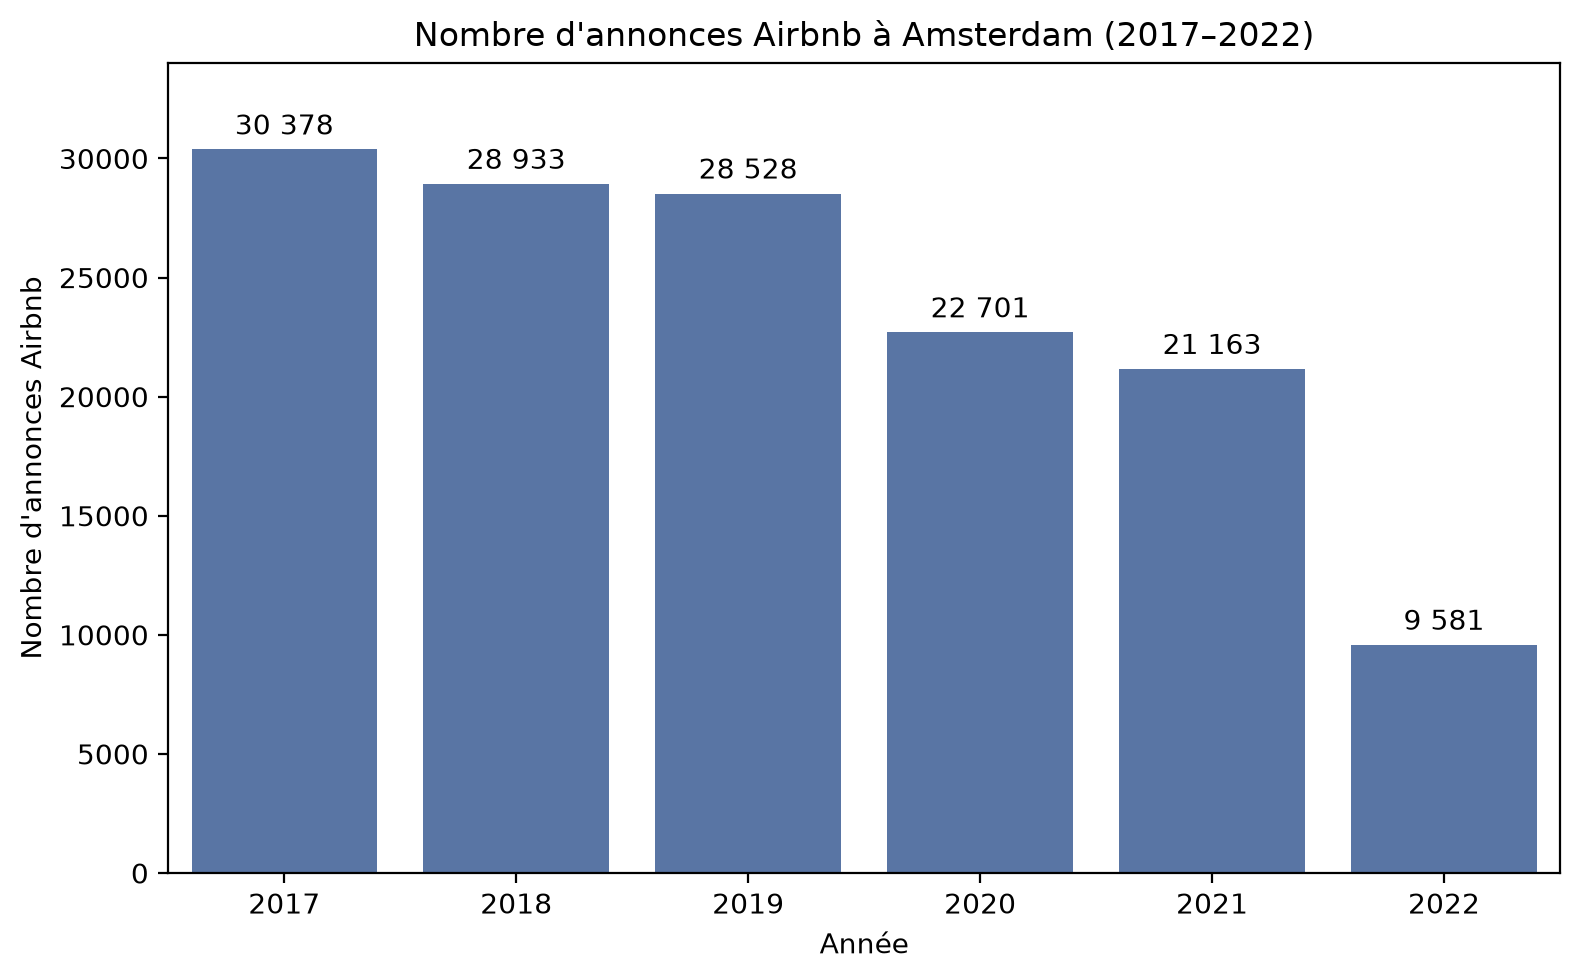

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Charger l'onglet 'data', filtrer sur 2017–2022 et trier par année
df = pd.read_excel("BHVESTAIRBNB-2019-gemeenten.xlsx", sheet_name="data")
df_plot = df[(df["Year"] >= 2017) & (df["Year"] <= 2022)].sort_values("Year")

# 2. Créer le barplot
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_plot, x="Year", y="Airbnb listings", color="#4C72B0", legend=False
)

# Ajouter les étiquettes de valeur au-dessus de chaque barre
for container in ax.containers:
    labels = [f"{int(bar.get_height()):,}".replace(",", " ") for bar in container]
    ax.bar_label(container, labels=labels, padding=3)

plt.ylim(0, df_plot["Airbnb listings"].max() * 1.12)
plt.title("Nombre d'annonces Airbnb à Amsterdam (2017–2022)")
plt.xlabel("Année")
plt.ylabel("Nombre d'annonces Airbnb")
plt.tight_layout()
plt.show()

Les données du tableau et du graphique ci-dessus proviennent toutes de **la section 'Recherche et statistique' (*Onderzoek en Statistiek*) du site de la ville d'Amsterdam**, consultable en anglais :  
https://onderzoek.amsterdam.nl/interactief/dashboard-kerncijfers?tab=indicator&thema=bevolking&indicator=BEVTOTAAL&indeling=ggwgebieden&jaar=2026&gebied=GA01&taal=en

### • Partie B3 – Réponses aux questions Q1 à Q4

#### Q1 – Taille et dynamique du marché

**• Nombre et part des annonces actives selon votre définition, et comment ce chiffre change avec une autre définition raisonnable**

In [7]:
nb_active = int(listclean['active'].sum()) # Nombre d'annonces actives
pct_active = round((nb_active/len(listclean['active']))*100, 2) # Pourcentage d'annonces actives
print("Nombre d'annonces actives :", nb_active)
print("Pourcentage d'annonces actives :", pct_active)

Nombre d'annonces actives : 6143
Pourcentage d'annonces actives : 57.89


In [8]:
# Avec une autre définition : on peut aussi utiliser 'availability_365' > 0
# (soit au moins une nuit de disponible dans l'année à venir)
nb_available = int((listclean['availability_365'] > 0).sum())
pct_available = round((nb_available/len(listclean['availability_365']))*100, 2)
print("Nombre d'annonces actives :", nb_available)
print("Pourcentage d'annonces actives :", pct_available)

Nombre d'annonces actives : 6152
Pourcentage d'annonces actives : 57.97


Les deux valeurs sont très proches (< 10 annonces d'écart) et correspondent à environ **58 %** du nombre total d'annonces.

On peut le comparer visuellement aux années précédentes :

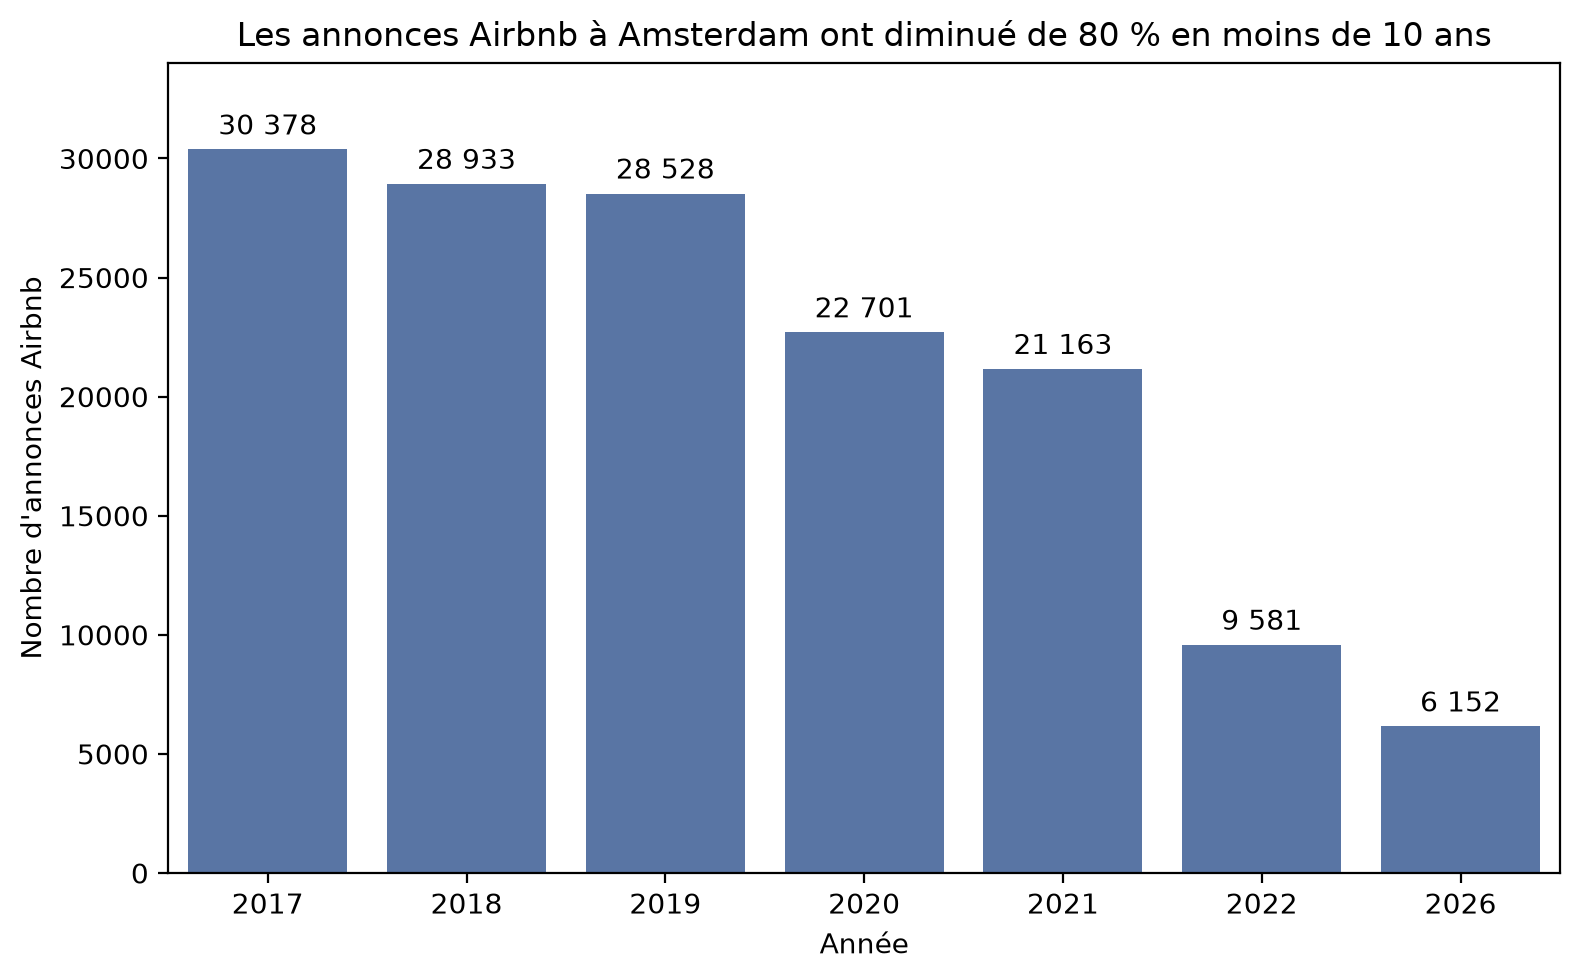

In [9]:
df.loc[len(df)] = [2026, 'gemeenten', 363, 'Amsterdam', 6152]
df_plot = df[(df["Year"] >= 2017) & (df["Year"] <= 2026)].sort_values("Year")

# 2. Créer le barplot
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_plot, x="Year", y="Airbnb listings", color="#4C72B0", legend=False
)

# Ajouter les étiquettes de valeur au-dessus de chaque barre
for container in ax.containers:
    labels = [f"{int(bar.get_height()):,}".replace(",", " ") for bar in container]
    ax.bar_label(container, labels=labels, padding=3)

plt.ylim(0, df_plot["Airbnb listings"].max() * 1.12)
plt.title("Les annonces Airbnb à Amsterdam ont diminué de 80 % en moins de 10 ans")
plt.xlabel("Année")
plt.ylabel("Nombre d'annonces Airbnb")
plt.tight_layout()
plt.show()

On constate que la baisse la plus drastique reste celle d'après 2021, qui correspond à la publication de l'étude de 2021 (van Haaren et al., 2021 – voir section A1), publiée par l'Union Européenne, qui montrait l'impact négatif d'Airbnb sur le coût et la qualité de la vie à Amsterdam et a entraîné la mise en place de nombreuses restrictions légales sur les locations de courte durée (voir A1). Depuis 2024, la législation s'est encore durcie, ce qui explique le chiffre encore plus faible pour l'année 2026.

**• Saisonnalité de l’activité (nombre d’avis par mois) : quels mois portent le revenu?**

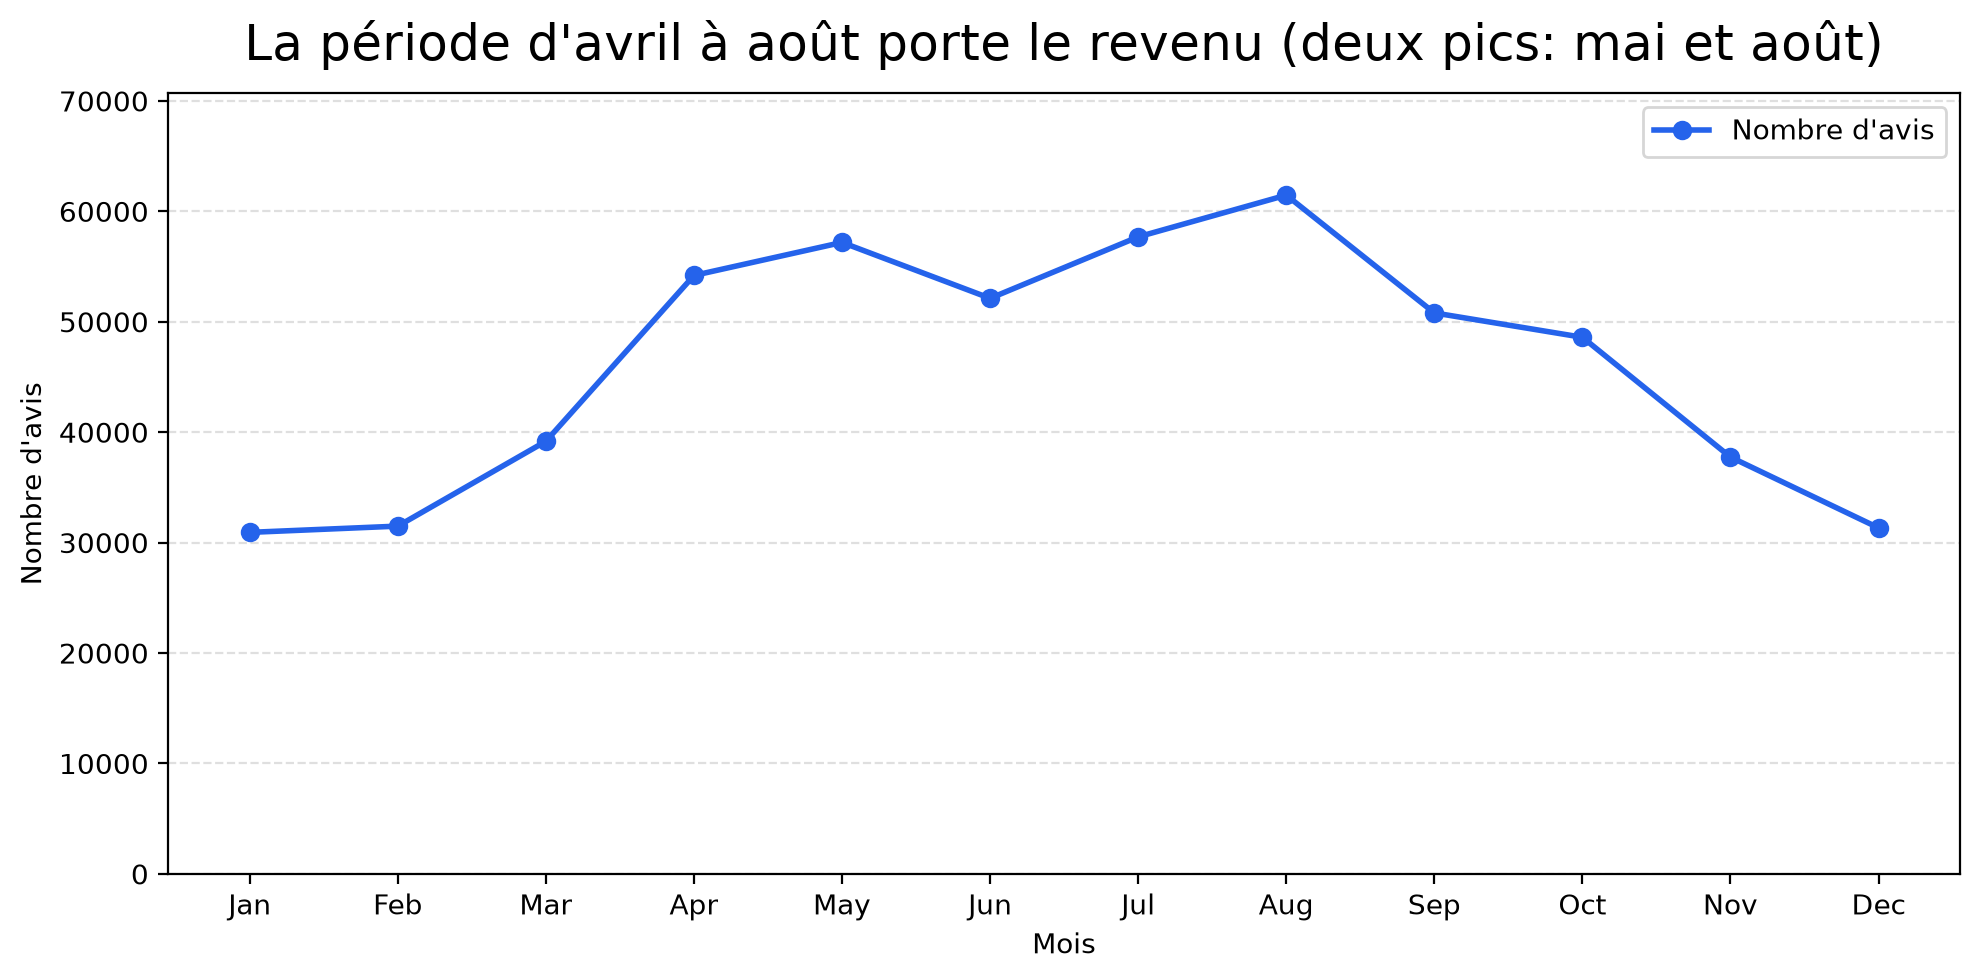

In [10]:
# On extrait le nombre d'avis par mois à partir de la colonne 'date' de 'revclean'
revclean['month'] = revclean['date'].dt.month

# Nombre total d'avis pour chaque mois
monthly_reviews = revclean.groupby('month').size().reset_index(name='review_count')

# Visualisation de la série temporelle
import matplotlib.dates as mdates
import calendar

## Convertir les nombres de 1 à 12 en noms des mois et les trier chronologiquement
monthly_reviews['month_label'] = monthly_reviews['month'].map(lambda m: calendar.month_abbr[int(m)])

order = [calendar.month_abbr[m] for m in range(1, 13)]
monthly_reviews['month_label'] = pd.Categorical(monthly_reviews['month_label'], categories=order, ordered=True)
monthly_reviews = monthly_reviews.sort_values('month_label')

## Graphique
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    monthly_reviews['month_label'],
    monthly_reviews['review_count'],
    marker="o",
    linewidth=2,
    color="#2563EB",
    label="Nombre d'avis",
)

## Commencer l'axe des ordonnées à 0 
ax.set_ylim(0, max(monthly_reviews['review_count']) * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.4)

## Titre et axes
ax.set_title("La période d'avril à août porte le revenu (deux pics: mai et août)", fontsize=18, pad=12)
ax.set_xlabel("Mois")
ax.set_ylabel("Nombre d'avis")
ax.legend()

plt.tight_layout()
plt.show()

Il faut nuancer ce résultat par un biais probable : un nombre important d'annonces (environ 38 % – nombre de lignes dans 'group' divisé par celui de 'listclean') n'ont pas d'avis disponibles dans le jeu de données. Le nombre de nuitées réellement réservées par mois serait donc sans doute assez différent de ce graphique, et potentiellement plus informatif.

#### Q2 – Concurrence



**• Part des annonces et du revenu estimé détenue par les hôtes multi-annonces**

On extrait les lignes correspondant à des hôtes multi-annonces pour estimer leur part de marché :

In [11]:
# Part des annonces
multihost_pct = round(int(fulldata['multi_host'].sum())/len(fulldata)*100, 2)

# Part du revenu
multihost_rev = fulldata.loc[fulldata['multi_host'] == True, 'estimated_revenue_l365d'].sum()
multihost_pctrev = round(multihost_rev/fulldata['estimated_revenue_l365d'].sum()*100, 2)

print("Les hôtes multi-annonces représentent", multihost_pct, "% des annonces et", multihost_pctrev, "% du revenu total.")

Les hôtes multi-annonces représentent 18.71 % des annonces et 37.36 % du revenu total.


Ces chiffres sont très faibles par rapport à la moyenne mondiale (62,9 % des annonces, voir [ici](https://insideairbnb.com/fr/report/the-threat-of-short-term-rentals-to-housing/)), ce qui était attendu au vu de l'interdiction de louer sa résidence secondaire à Amsterdam.

**• Part détenue par les 10 % d’hôtes les plus actifs**

On commence par compter les hôtes les plus actifs et extraire le décile supérieur de la distribution.

In [12]:
from collections import Counter
import math

mostactive = Counter(fulldata['host_id'])
n_top = max(1, math.ceil(len(mostactive) * 0.10))

top_10_pct = mostactive.most_common(n_top)
print("Il y a", len(top_10_pct), "hôtes représentant les 10% les plus actifs du total de", len(mostactive), "hôtes.")

Il y a 924 hôtes représentant les 10% les plus actifs du total de 9231 hôtes.


In [13]:
# Part de marché détenue par ces 10 %

top_ids = [pair[0] for pair in top_10_pct] # Extraction de l'ID des hôtes

matched_mask = fulldata['host_id'].isin(top_ids) # Match des ID des deux data frames

## Pour le nombre d'annonces :
top_sum = fulldata.loc[matched_mask, 'host_id'].count() # Compte des annonces des 10%
total_sum = fulldata['host_id'].count() # Compte du nombre total d'annonces

share_proportion = round(top_sum / total_sum, 2)
share_percent = round((top_sum / total_sum) * 100, 2)

## Pour le revenu :
top_rev = fulldata.loc[matched_mask, 'estimated_revenue_l365d'].sum() # Revenu des 10%
total_rev = fulldata['estimated_revenue_l365d'].sum() # Revenu total du jeu de données

rev_prop = round(top_rev / total_rev, 2)
rev_percent = round((top_rev / total_rev) * 100, 2)

print("Les 10 % d'hôtes les plus actifs cumulent", share_percent, "% des annonces et", rev_percent, "% du revenu total.")

Les 10 % d'hôtes les plus actifs cumulent 21.72 % des annonces et 39.86 % du revenu total.


10 % des hôtes représentent 40 % du revenu : on a bien une concentration du marché dans une minorité d'utilisateurs multi-annonces de la plateforme à Amsterdam.

**• Courbe de Lorenz et indice de Gini du revenu par hôte**

Indice de Gini : 0.68


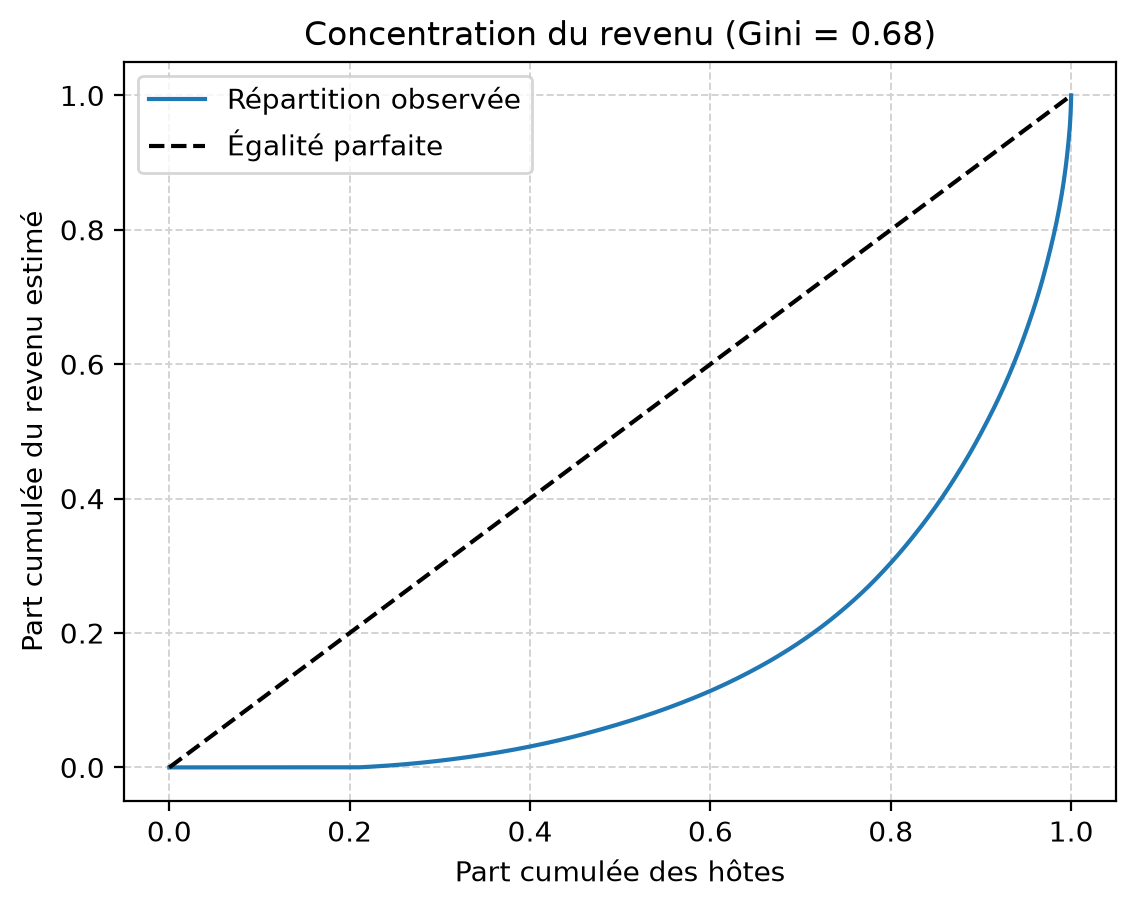

In [14]:
revenu_par_hote = fulldata.dropna(subset=["estimated_revenue_l365d"]).groupby("host_id")["estimated_revenue_l365d"].sum()
revenus = np.sort(revenu_par_hote.values) # Du plus petit au plus grand

part_hotes = np.concatenate([[0], np.arange(1, len(revenus) + 1) / len(revenus)])
part_revenu = np.concatenate([[0], np.cumsum(revenus) / revenus.sum()])

gini = 1 - 2 * np.trapezoid(part_revenu, part_hotes) # np.trapz avec NumPy < 2
print(f"Indice de Gini : {gini:.2f}")

plt.plot(part_hotes, part_revenu, label="Répartition observée")
plt.plot([0, 1], [0, 1], linestyle="--", color="black", label="Égalité parfaite")
plt.grid(color='lightgrey', linestyle='--', linewidth=0.7)
plt.xlabel("Part cumulée des hôtes")
plt.ylabel("Part cumulée du revenu estimé")
plt.title(f"Concentration du revenu (Gini = {gini:.2f})")
plt.legend()
plt.show()

En accord avec le haut pourcentage de revenu contrôlé par les 10% d'hôtes les plus actifs, la répartition des revenus est **extrêmement inégalitaire** : environ 25 % des hôtes contrôlent 80 % du revenu total ! Il y a donc déjà une minorité d'hôtes à très hauts revenus qui contrôlent l'essentiel du marché.

#### Q3 – Où investir

**• Nombre d’annonces, prix médian, occupation médiane et revenu médian par quartier**

On sépare ces indicateurs par type de logement : il n'est pas pertinent de grouper ensemble les chambres individuelles avec les logements entiers, qui présentent des prix, occupations, etc. très différents.

In [15]:
# Pivot table avec 'room_type' : on liste les prix, occupation et revenu médians 
# pour chaque type de logement listé
# (Logement entier, chambre privée, chambre partagée, ou chambre d'hôtel)

ordre_colonnes = ["id", "price", "estimated_occupancy_l365d", "estimated_revenue_l365d"]
# Pour conserver les colonnes dans le bon ordre (défaut : ordre alphabétique)

pivot_ams = fulldata.pivot_table(
    index="neighbourhood_cleansed",
    columns="room_type",
    values=ordre_colonnes,
    aggfunc={
        "id": "count",
        "price": "median",
        "estimated_occupancy_l365d": "median",
        "estimated_revenue_l365d": "median",
    },
)

pivot_ams = pivot_ams.reindex(columns=ordre_colonnes, level=0)

pivot_ams.columns = ['Nombre d’annonces – logement entier',
                    'Nombre d’annonces – chambre d’hôtel',
                    'Nombre d’annonces – chambre privée',
                    'Nombre d’annonces – chambre partagée',
                    'Prix médian – logement entier',
                    'Prix médian – chambre d’hôtel',
                    'Prix médian – chambre privée',
                    'Prix médian – chambre partagée',
                    'Occupation médiane – logement entier', 
                    'Occupation médiane – chambre d’hôtel', 
                    'Occupation médiane – chambre privée',
                    'Occupation médiane – chambre partagée',
                    'Revenu médian – logement entier',
                    'Revenu médian – chambre d’hôtel',
                    'Revenu médian – chambre privée',
                    'Revenu médian – chambre partagée'
]

pivot_ams

,Nombre d’annonces – logement entier,Nombre d’annonces – chambre d’hôtel,Nombre d’annonces – chambre privée,Nombre d’annonces – chambre partagée,Prix médian – logement entier,Prix médian – chambre d’hôtel,Prix médian – chambre privée,Prix médian – chambre partagée,Occupation médiane – logement entier,Occupation médiane – chambre d’hôtel,Occupation médiane – chambre privée,Occupation médiane – chambre partagée,Revenu médian – logement entier,Revenu médian – chambre d’hôtel,Revenu médian – chambre privée,Revenu médian – chambre partagée
neighbourhood_cleansed,,,,,,,,,,,,,,,,
Bijlmer-Centrum,25.0,10.0,26.0,NaN,175.000,181.600,114.000,NaN,8.0,0.0,255.0,NaN,2076.0,0.0,22695.0,NaN
Bijlmer-Oost,29.0,NaN,13.0,NaN,203.785,NaN,115.250,NaN,20.0,NaN,112.0,NaN,6561.0,NaN,14476.0,NaN
Bos en Lommer,533.0,NaN,41.0,NaN,282.500,NaN,119.000,NaN,8.0,NaN,78.0,NaN,6509.0,NaN,10529.0,NaN
Buitenveldert - Zuidas,93.0,NaN,30.0,NaN,301.000,NaN,142.750,NaN,8.0,NaN,44.5,NaN,7984.0,NaN,5022.0,NaN
Centrum-Oost,618.0,3.0,335.0,8.0,368.000,243.000,197.000,57.00,16.0,0.0,101.0,167.5,14080.0,0.0,22274.0,7185.5
Centrum-West,764.0,3.0,466.0,1.0,402.750,302.835,220.000,591.41,23.0,255.0,207.0,109.0,18841.5,39404.0,38231.0,64464.0
De Aker - Nieuw Sloten,47.0,NaN,24.0,NaN,233.000,NaN,155.100,NaN,0.0,NaN,86.0,NaN,2937.0,NaN,19995.0,NaN
De Baarsjes - Oud-West,1641.0,3.0,192.0,NaN,354.000,166.000,149.000,NaN,14.0,172.0,179.0,NaN,8553.5,20885.0,23561.0,NaN
De Pijp - Rivierenbuurt,1050.0,NaN,139.0,NaN,373.350,NaN,174.000,NaN,8.0,NaN,195.0,NaN,7739.0,NaN,31875.0,NaN


Quelques observations générales :

**a)** Les logements entiers et chambres privées sont beaucoup plus fréquents que les chambres d'hôtels et chambres partagées, qui sont totalement absentes de la plupart des quartiers (seulement présentes dans 7 et 5 des 22 quartiers, soit 32% et 23%, respectivement) ;

**b)** Selon les quartiers, le prix médian peut varier énormément (du simple au double, les prix les plus élevés correspondant aux quartiers du centre historique) ;

**c)** Les revenus médians les plus élevés sont deux quartiers du centre historiques (Centrum-Oost et Centrum-West), suivi par Osdorp, un quartier un peu plus excentré mais beaucoup moins cher – sans doute un bon compromis pour les touristes ;

**d)** L'occupation médiane des chambres individuelles est beaucoup plus élevée que celle des logements entiers, ce qui est dû aux restrictions de 30 ou 15 jours maximum d'occupation par an pour ces derniers.

**• Densité de concurrence : annonces actives pour 1000 habitants**

On peut calculer ce chiffre pour l'ensemble de la ville et par quartier (données extraites du site de la ville d'Amsterdam, voir plus haut). On se focalise sur les logements entiers et les chambres privées, les deux autres catégories étant très peu représentées.

In [16]:
df2 = dfQ.set_index('Quartier') # Définir les quartiers comme index pour joindre les deux tableaux

amsterdata = pd.concat([pivot_ams, df2], axis=1)
# (Deux quartiers d'Amsterdam non représentés dans le jeu de données)

## Pour chaque quartier :
amsterdata['conc_density_room'] = (amsterdata['Nombre d’annonces – chambre privée']/amsterdata['Population'])*1000
amsterdata['conc_density_home'] = (amsterdata['Nombre d’annonces – logement entier']/amsterdata['Population'])*1000
## Pour toute la ville :
conc_room_ams = round((amsterdata['Nombre d’annonces – chambre privée'].sum()/amsterdata['Population'].sum())*1000, 1)
conc_home_ams = round((amsterdata['Nombre d’annonces – logement entier'].sum()/amsterdata['Population'].sum())*1000, 1)

# On peut aussi comparer quel proportion du nombre total de logements (en ‰) est mise en location sur Airbnb
## Pour chaque quartier :
amsterdata['Pct_Airbnb'] = (amsterdata['Nombre d’annonces – logement entier']/amsterdata['Nb_logements'])*100
## Pour toute la ville :
pct_airbnb_ams = round((amsterdata['Nombre d’annonces – logement entier'].sum()/amsterdata['Nb_logements'].sum())*100, 2)

print("Il y a", conc_home_ams, "annonces actives de logements entiers et", conc_room_ams, "annonces actives de chambres d'hôte pour 1000 habitants à Amsterdam.")
print(pct_airbnb_ams, "% des logements à Amsterdam sont mis en location sur Airbnb.")

Il y a 9.1 annonces actives de logements entiers et 2.1 annonces actives de chambres d'hôte pour 1000 habitants à Amsterdam.
1.74 % des logements à Amsterdam sont mis en location sur Airbnb.


Ces chiffres sont à comparer à ceux d'autres capitales européennes (voir données [ici](https://letbloom.io/fr/articles/airbnb-listings-per-resident-europe)): 

Pour les logements entiers, Amsterdam compte une proportion d'annonce active pour 1000 habitants inférieure à celles d'autres métropoles très touristiques comme Athènes (36,9) ou Paris (22,3), mais plus élevée que celle de Madrid (6,5) ou Berlin (3,5).

Le nombre d'annonces en valeur absolue à Amsterdam est beaucoup plus faible que pour ces autres villes, mais la population est aussi beaucoup plus petite (moins d'un million d'habitants), d'où une proportion d'annonces actives dans la moyenne de l'Europe.

**• Classement argumenté des quartiers les plus favorables**

Ici, il faut comparer les différents indicateurs à notre disposition : ils ne sont pas équivalents et renvoient des informations distinctes et complémentaires les unes des autres.

- Le revenu médian est un bon critère de rendement : plus il est élevé, plus le prix et l'occupation sont élevés.
- Le prix médian et l'occupation médiane sont utiles car ils indiquent le profil du marché, mais ils sont redondants avec le revenu, qui inclut déjà ces paramètres pour être calculé puisqu'il est une approximation basée sur le prix de la nuitée et le taux d'occupation ; il faut donc les pondérer en conséquence.
- La densité de concurrence et la proportion de logements loués sont des critères négatifs : plus ils sont élevés, plus le marché d'un quartier est déjà saturé et soumis à des restrictions légales.
- Le nombre d'annonces est plutôt à utiliser comme un filtre (les quartiers avec trop peu d'annonces ne permettent pas une analyse suffisamment poussée pour en évaluer le profil).

On se concentre sur les logements entiers, les chambres d'hôtes étant trop restrictives (uniquement accessibles aux particuliers physiquement présents dans le bien, ce qui limite énormément la rentabilité de l'investissement).

In [17]:
# On commence par pondérer nos indicateurs, qui sont tous dans des unités différentes
# et sur des échelles différentes : on utilise une normalisation mix-max pour les critères positifs,
# et max-min pour les critères négatifs

# Min-max : revenu médian, occupation médiane
revenu_med = (amsterdata['Revenu médian – logement entier']-min(amsterdata['Revenu médian – logement entier']))/(max(amsterdata['Revenu médian – logement entier'])-min(amsterdata['Revenu médian – logement entier']))*100
occup_med = (amsterdata['Occupation médiane – logement entier']-min(amsterdata['Occupation médiane – logement entier']))/(max(amsterdata['Occupation médiane – logement entier'])-min(amsterdata['Occupation médiane – logement entier']))*100
# Max-min : densité de concurrence, proportion de logements loués
dens_conc = (max(amsterdata['conc_density_home'])-amsterdata['conc_density_home'])/(max(amsterdata['conc_density_home'])-min(amsterdata['conc_density_home']))*100
prop_loc = (max(amsterdata['Pct_Airbnb'])-amsterdata['Pct_Airbnb'])/(max(amsterdata['Pct_Airbnb'])-min(amsterdata['Pct_Airbnb']))*100

# Créer une data frame avec ces quatre paramètres
ranking = pd.concat([revenu_med, occup_med, dens_conc, prop_loc], axis=1)

# Pondérer les paramètres et compiler un score final global pour chaque quartier
## On privilégie le revenu (rentabilité brute – 45 %), 
## puis les critères négatifs (densité de concurrence et proportion de logements loués – 20 % chacun),
## puis le taux d'occupation (15 %, moins important car déjà pris en compte pour estimer le revenu)
ranking['Total Score'] = ranking.dot([0.45,0.15,0.2,0.2])
ranking.sort_values('Total Score', ascending=False)

,Revenu médian – logement entier,Occupation médiane – logement entier,conc_density_home,Pct_Airbnb,Total Score
Osdorp,55.232471,93.478261,98.397424,98.012120,78.158260
Centrum-West,100.000000,100.000000,24.671967,37.141793,72.362752
Bijlmer-Oost,26.751364,86.956522,98.169961,97.590484,64.233681
Centrum-Oost,71.599415,69.565217,43.039963,46.875278,60.637568
Buitenveldert - Zuidas,35.239033,34.782609,88.156579,88.607716,56.427815
Noord-Oost,25.534580,69.565217,84.793079,81.606012,55.205162
Slotervaart,30.661179,34.782609,86.581903,85.086981,53.348699
Geuzenveld - Slotermeer,19.647490,34.782609,91.922014,89.188566,50.280878
Oud-Noord,32.447586,69.565217,53.116274,51.947944,46.049040
Noord-West,17.607587,69.565217,72.089242,62.380981,45.252241


In [18]:
# Classer les valeurs du score final en catégories discrètes
# ('Rendement élevé', 'Bon potentiel', 'À éviter')
part = (1/3)*(max(ranking['Total Score'])-min(ranking['Total Score'])) # Intervalle de la distribution
lim1 = min(ranking['Total Score'])+part # Tiers inférieur
lim2 = max(ranking['Total Score'])-part # Tiers supérieur

# On assigne les catégories aux quartiers
bornes = [0, lim1, lim2, 100]
categories = ['à éviter', 'bon potentiel', 'rendement élevé']

ranking["recommendation"] = pd.cut(
    ranking["Total Score"],
    bins=bornes,
    labels=categories,
    include_lowest=True,
)

ranking.sort_values('Total Score', ascending=False)

,Revenu médian – logement entier,Occupation médiane – logement entier,conc_density_home,Pct_Airbnb,Total Score,recommendation
Osdorp,55.232471,93.478261,98.397424,98.012120,78.158260,rendement élevé
Centrum-West,100.000000,100.000000,24.671967,37.141793,72.362752,rendement élevé
Bijlmer-Oost,26.751364,86.956522,98.169961,97.590484,64.233681,rendement élevé
Centrum-Oost,71.599415,69.565217,43.039963,46.875278,60.637568,bon potentiel
Buitenveldert - Zuidas,35.239033,34.782609,88.156579,88.607716,56.427815,bon potentiel
Noord-Oost,25.534580,69.565217,84.793079,81.606012,55.205162,bon potentiel
Slotervaart,30.661179,34.782609,86.581903,85.086981,53.348699,bon potentiel
Geuzenveld - Slotermeer,19.647490,34.782609,91.922014,89.188566,50.280878,bon potentiel
Oud-Noord,32.447586,69.565217,53.116274,51.947944,46.049040,bon potentiel
Noord-West,17.607587,69.565217,72.089242,62.380981,45.252241,bon potentiel


In [19]:
# On affiche les quartiers avec un rendement élevé ou bon :
for cat in ["rendement élevé", "bon potentiel"]:
    quartiers = ranking.index[ranking["recommendation"]==cat].dropna().unique()
    texte = ", ".join(quartiers) if len(quartiers) > 0 else "aucun"
    print(f"Les quartiers avec un {cat.lower()} sont : {texte}")

Les quartiers avec un rendement élevé sont : Bijlmer-Oost, Centrum-West, Osdorp
Les quartiers avec un bon potentiel sont : Bijlmer-Centrum, Buitenveldert - Zuidas, Centrum-Oost, Geuzenveld - Slotermeer, IJburg - Zeeburgereiland, Noord-Oost, Noord-West, Oud-Noord, Slotervaart


Pour conclure sur le classement des quartiers :

- Les quartiers avec un rendement élevé sont : **Bijlmer-Oost, Centrum-West,** et **Osdorp**.
- Les quartiers avec un bon potentiel sont : **Bijlmer-Centrum, Buitenveldert - Zuidas, Centrum-Oost, Geuzenveld - Slotermeer, IJburg - Zeeburgereiland, Noord-Oost, Noord-West, Oud-Noord,** et **Slotervaart**.
- Les autres quartier sont à éviter (rendement trop faible et/ou concurrence trop élevée).

#### Q4 – Cadre légal

**• Part des annonces avec et sans valeur dans 'license' et formats rencontrés**

In [20]:
fulldata['statut_licence'].value_counts()

statut_licence
renseigné        9541
exempté           605
non renseigné     466
Name: count, dtype: int64

9541 licences renseignées, soit 90 % des annonces listées.  
Sur les 10 % restants, 6 % sont exemptés et 4 % n'ont pas renseigné de numéro de licence.

**• Lien avec la durée minimale de séjour, le type de logement, et le cadre légal**

Comme montré dans la section A1 (voir Notebook A), *une licence est obligatoire pour louer un bien en location courte durée*. Les exemptions correspondent aux hôtels, qui ont un autre type de permis mais peuvent lister des chambres sur Airbnb, ou aux Bed & Breakfast, qui sont soumis aux mêmes types de restrictions que les chambres d'hôtes (voir A1) et ne s'appliquent qu'aux propriétés habitées à l'année par l'hôte.  
*Airbnb limite par défaut à 60 nuitées par an toutes les annonces à Amsterdam* et [empêche ses utilisateurs de sortir du cadre légal établi par la municipalité](https://www.airbnb.fr/help/article/1624).

Par conséquent, à moins d'avoir le statut d'hôtel, **il est impossible de louer une propriété à Amsterdam pour une courte durée sans y résider le reste de l'année**.

Le statut d'hôtel ne peut être obtenu qu'à la suite d'une longue évaluation de la mairie et est soumis à un quota strict – il faut qu'un hôtel déjà existant ferme et que son successeur prouve qu'il ne dépasse pas la capacité d'occupation totale autorisée par la ville avec son nouveau projet – [voir ici](https://www.amsterdam.nl/ondernemen/horeca/horecavergunning-aanvragen/).


**• Conséquence pour l’investisseur : quel modèle de location est possible et à quelles conditions**

Notre conclusion au vu du cadre légal est que le modèle suivi par Amsterdam est **trop restrictif pour un investissement immobilier depuis l'étranger dans la location courte durée à l'échelle d'une entreprise**. Seules les locations par des particuliers sur de très courtes durées, au rendement trop faible pour être rentable comme source de revenu principal à l'année, sont autorisées.

La seule alternative consisterait à **investir dans une entreprise immobilière déjà implantée à Amsterdam** ; toutefois, même dans ce cas de figure, un marché extrêmement saturé et soumis à des quotas très stricts empêcherait une croissance régulière de la part de marché et du rendement, limitant énormément un potentiel retour sur investissement sur le long terme.